In [128]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, StandardScaler

df = pd.read_csv('../pliki/stroke-dataset.csv')
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [129]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


In [130]:
df.duplicated().sum() # 0 duplikatów

np.int64(0)

In [131]:
df.isnull().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [132]:
df.isna().mean().sort_values(ascending=False)

bmi                  0.039335
id                   0.000000
age                  0.000000
gender               0.000000
hypertension         0.000000
heart_disease        0.000000
work_type            0.000000
ever_married         0.000000
Residence_type       0.000000
avg_glucose_level    0.000000
smoking_status       0.000000
stroke               0.000000
dtype: float64

### mały procent braków w kolumnie bmi, więc uzupełniamy medianą

In [133]:
df["bmi"] = df["bmi"].fillna(df["bmi"].median())
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                5110 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


### usunięcie zbędnej kolumny id

In [134]:
df = df.drop(columns=["id"])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             5110 non-null   str    
 1   age                5110 non-null   float64
 2   hypertension       5110 non-null   int64  
 3   heart_disease      5110 non-null   int64  
 4   ever_married       5110 non-null   str    
 5   work_type          5110 non-null   str    
 6   Residence_type     5110 non-null   str    
 7   avg_glucose_level  5110 non-null   float64
 8   bmi                5110 non-null   float64
 9   smoking_status     5110 non-null   str    
 10  stroke             5110 non-null   int64  
dtypes: float64(3), int64(3), str(5)
memory usage: 439.3 KB


### kodowanie danych kategorycznych

In [135]:
# kolumna ever_married = Yes/No
le = LabelEncoder()
df["ever_married"] = le.fit_transform(df["ever_married"])
df.head(15)


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,1,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,1,Self-employed,Rural,202.21,28.1,never smoked,1
2,Male,80.0,0,1,1,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,1,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,1,Self-employed,Rural,174.12,24.0,never smoked,1
5,Male,81.0,0,0,1,Private,Urban,186.21,29.0,formerly smoked,1
6,Male,74.0,1,1,1,Private,Rural,70.09,27.4,never smoked,1
7,Female,69.0,0,0,0,Private,Urban,94.39,22.8,never smoked,1
8,Female,59.0,0,0,1,Private,Rural,76.15,28.1,Unknown,1
9,Female,78.0,0,0,1,Private,Urban,58.57,24.2,Unknown,1


In [136]:
df['Residence_type'].unique()

<StringArray>
['Urban', 'Rural']
Length: 2, dtype: str

In [137]:
df["Residence_type"] = le.fit_transform(df["Residence_type"])
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,1,Private,1,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,1,Self-employed,0,202.21,28.1,never smoked,1
2,Male,80.0,0,1,1,Private,0,105.92,32.5,never smoked,1
3,Female,49.0,0,0,1,Private,1,171.23,34.4,smokes,1
4,Female,79.0,1,0,1,Self-employed,0,174.12,24.0,never smoked,1


### one-hot dla work_type

In [138]:
df['work_type'].unique()

<StringArray>
['Private', 'Self-employed', 'Govt_job', 'children', 'Never_worked']
Length: 5, dtype: str

In [139]:
df = pd.get_dummies(df, columns=["work_type"], dtype=int)
df.head()

,gender,age,hypertension,heart_disease,ever_married,Residence_type,avg_glucose_level,bmi,smoking_status,stroke,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children
0,Male,67.0,0,1,1,1,228.69,36.6,formerly smoked,1,0,0,1,0,0
1,Female,61.0,0,0,1,0,202.21,28.1,never smoked,1,0,0,0,1,0
2,Male,80.0,0,1,1,0,105.92,32.5,never smoked,1,0,0,1,0,0
3,Female,49.0,0,0,1,1,171.23,34.4,smokes,1,0,0,1,0,0
4,Female,79.0,1,0,1,0,174.12,24.0,never smoked,1,0,0,0,1,0


### one-hot dla smoking_status

In [140]:
df = pd.get_dummies(df, columns=["smoking_status"], dtype=int)
df.head()

,gender,age,hypertension,heart_disease,ever_married,Residence_type,avg_glucose_level,bmi,stroke,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,Male,67.0,0,1,1,1,228.69,36.6,1,0,0,1,0,0,0,1,0,0
1,Female,61.0,0,0,1,0,202.21,28.1,1,0,0,0,1,0,0,0,1,0
2,Male,80.0,0,1,1,0,105.92,32.5,1,0,0,1,0,0,0,0,1,0
3,Female,49.0,0,0,1,1,171.23,34.4,1,0,0,1,0,0,0,0,0,1
4,Female,79.0,1,0,1,0,174.12,24.0,1,0,0,0,1,0,0,0,1,0


### ona-hot dla gender

In [141]:
df['gender'].unique()

<StringArray>
['Male', 'Female', 'Other']
Length: 3, dtype: str

In [142]:
df = pd.get_dummies(df, columns=["gender"], dtype=int)
df.head()

,age,hypertension,heart_disease,ever_married,Residence_type,avg_glucose_level,bmi,stroke,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,gender_Female,gender_Male,gender_Other
0,67.0,0,1,1,1,228.69,36.6,1,0,0,1,0,0,0,1,0,0,0,1,0
1,61.0,0,0,1,0,202.21,28.1,1,0,0,0,1,0,0,0,1,0,1,0,0
2,80.0,0,1,1,0,105.92,32.5,1,0,0,1,0,0,0,0,1,0,0,1,0
3,49.0,0,0,1,1,171.23,34.4,1,0,0,1,0,0,0,0,0,1,1,0,0
4,79.0,1,0,1,0,174.12,24.0,1,0,0,0,1,0,0,0,1,0,1,0,0


### standaryzacja Z-score, aby wartości nie były tylko w zakresie 0-1 => średnia=0, std=1, a min-max jest wrażliwa na outliery

In [143]:
standard = StandardScaler()

df_standard = df.copy()
df_standard[["age", "avg_glucose_level", "bmi"]] = standard.fit_transform(df_standard[["age", "avg_glucose_level", "bmi"]])

df_standard[["age", "avg_glucose_level", "bmi"]].describe()
df_standard.head()

,age,hypertension,heart_disease,ever_married,Residence_type,avg_glucose_level,bmi,stroke,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,gender_Female,gender_Male,gender_Other
0,1.051434,0,1,1,1,2.706375,1.005086,1,0,0,1,0,0,0,1,0,0,0,1,0
1,0.786070,0,0,1,0,2.121559,-0.098981,1,0,0,0,1,0,0,0,1,0,1,0,0
2,1.626390,0,1,1,0,-0.005028,0.472536,1,0,0,1,0,0,0,0,1,0,0,1,0
3,0.255342,0,0,1,1,1.437358,0.719327,1,0,0,1,0,0,0,0,0,1,1,0,0
4,1.582163,1,0,1,0,1.501184,-0.631531,1,0,0,0,1,0,0,0,1,0,1,0,0


### wykrywanie wartości odstających dla kolumny bmi

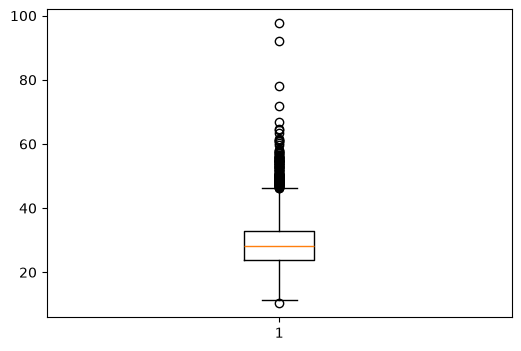

In [144]:
plt.figure(figsize=(6,4))
plt.boxplot(df["bmi"])
plt.show()

### metoda IQR

In [145]:
Q1 = df["bmi"].quantile(0.25)
Q3 = df["bmi"].quantile(0.75)
IQR = Q3-Q1

lower = Q1 - 1.5*IQR
upper = Q3 + 1.5*IQR
outliers = df[(df["bmi"] < lower) | (df["bmi"]>upper)]
print(f"Liczba wykrytych outlierów dla BMI: {len(outliers)}")
outliers.head()

Liczba wykrytych outlierów dla BMI: 126


,age,hypertension,heart_disease,ever_married,Residence_type,avg_glucose_level,bmi,stroke,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,gender_Female,gender_Male,gender_Other
21,52.0,1,0,1,1,233.29,48.9,1,0,0,0,1,0,0,0,1,0,1,0,0
66,70.0,0,0,1,1,221.58,47.5,1,0,0,1,0,0,0,0,1,0,1,0,0
113,45.0,0,0,1,0,224.10,56.6,1,0,0,1,0,0,0,0,1,0,1,0,0
254,47.0,0,0,1,1,210.95,50.1,0,0,0,1,0,0,1,0,0,0,1,0,0
258,74.0,1,0,1,1,205.84,54.6,0,0,0,0,1,0,0,0,1,0,1,0,0


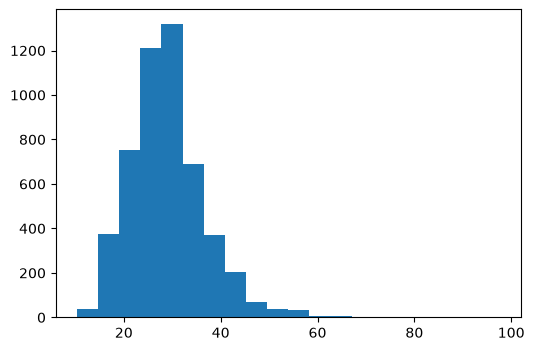

In [146]:
plt.figure(figsize=(6,4))
plt.hist(df["bmi"], bins=20)
plt.show()

In [147]:
# Analiza powiązania outlierów BMI ze zmienną stroke
outliers_stroke_count = outliers['stroke'].sum()
outliers_stroke_pct = (outliers_stroke_count / len(outliers)) * 100

print(f"Liczba osób z udarem w grupie outlierów BMI: {outliers_stroke_count}")
print(f"Procent osób z udarem w grupie outlierów BMI: {outliers_stroke_pct:.2f}%")

Liczba osób z udarem w grupie outlierów BMI: 3
Procent osób z udarem w grupie outlierów BMI: 2.38%


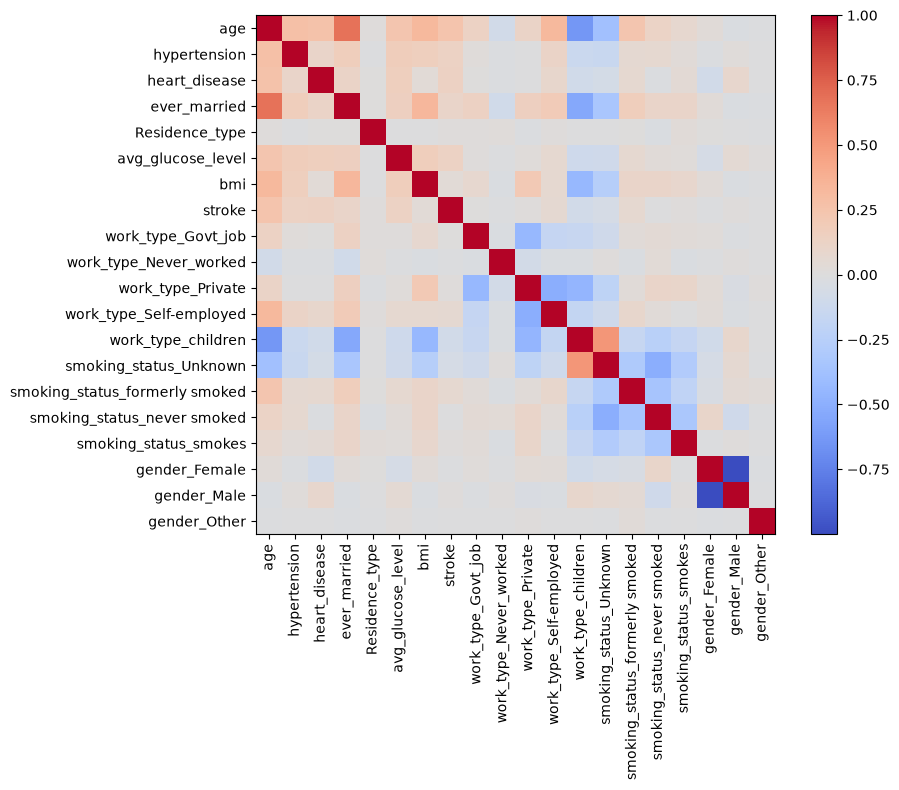

In [148]:
corr = df_standard.select_dtypes(include=np.number).corr()
corr

plt.figure(figsize=(10,8))
plt.imshow(corr, cmap="coolwarm", interpolation="nearest")
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.tight_layout()
plt.show()

### wyznaczamy zmienne zależne i niezależne

In [149]:
X = df.drop(columns=["stroke"])
X = X.select_dtypes(include=[np.number])

y=df["stroke"]

### wybieramy najlepsze cechy i usuwamy zbędne kolumny

In [150]:
from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(score_func=f_classif, k=5)
X_selected = selector.fit_transform(X,y)
selected_features = X.columns[selector.get_support()]
print(selected_features)
final_df = pd.concat([pd.DataFrame(X_selected, columns=selected_features), y.reset_index(drop=True)], axis=1)
X = final_df.drop(columns=["stroke"])
y = final_df["stroke"]

Index(['age', 'hypertension', 'heart_disease', 'ever_married',
       'avg_glucose_level'],
      dtype='str')


### dzielenie danych na zbiory treningowy i testowy

In [151]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print(X_train.shape)
print(X_test.shape)

(4088, 5)
(1022, 5)


(najpierw wybieramy zminne zalezne i zieazalezne, dzielimy zbiór i dopiero potem ptrzetwarzamy)

# Laboratorium 3 - ćwiczenie 1

In [152]:
import pandas as pd

df["AgeGroup"] = pd.cut(
    df["age"],
    bins=[0, 18, 31, 65, 100],
    labels=["Dziecko", "Młody", "Dorosły", "Senior"]
)

df["BMICategory"] = pd.cut(
    df["bmi"],
    bins=[0, 18.5, 26, 31, 100],
    labels=["Underweight", "NormalWeight", "Overweight", "Obese"]
)

In [153]:
df["AgeGroup"].value_counts()

AgeGroup
Dorosły    2496
Senior      965
Dziecko     916
Młody       733
Name: count, dtype: int64

In [154]:
df["BMICategory"].value_counts()

BMICategory
Obese           1665
Overweight      1590
NormalWeight    1506
Underweight      349
Name: count, dtype: int64

In [156]:
df.head()

,age,hypertension,heart_disease,ever_married,Residence_type,avg_glucose_level,bmi,stroke,work_type_Govt_job,work_type_Never_worked,...,work_type_children,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,gender_Female,gender_Male,gender_Other,AgeGroup,BMICategory
0,67.0,0,1,1,1,228.69,36.6,1,0,0,...,0,0,1,0,0,0,1,0,Senior,Obese
1,61.0,0,0,1,0,202.21,28.1,1,0,0,...,0,0,0,1,0,1,0,0,Dorosły,Overweight
2,80.0,0,1,1,0,105.92,32.5,1,0,0,...,0,0,0,1,0,0,1,0,Senior,Obese
3,49.0,0,0,1,1,171.23,34.4,1,0,0,...,0,0,0,0,1,1,0,0,Dorosły,Obese
4,79.0,1,0,1,0,174.12,24.0,1,0,0,...,0,0,0,1,0,1,0,0,Senior,NormalWeight


<Axes: xlabel='AgeGroup'>

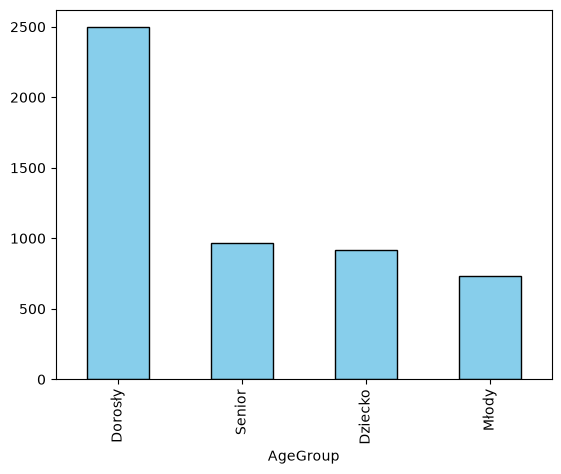

In [158]:
df["AgeGroup"].value_counts().plot(
    kind='bar', color='skyblue', edgecolor='black'
)


<Axes: xlabel='BMICategory'>

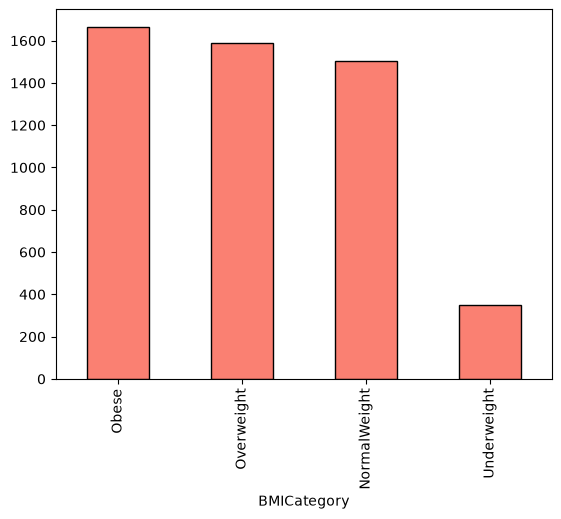

In [159]:
df["BMICategory"].value_counts().plot(
    kind='bar', color='salmon', edgecolor='black'
)